# VULNMINER — Notebook SEMMA

Ejecución académica reproducible de Sample, Explore, Modify, Model y Assess. Los registros sintéticos están identificados por procedencia y no se usan para el test independiente.

## 1. Sample

La fase de muestreo se realiza con `scripts/build_dataset.py`, a partir del OWASP Benchmark Java 1.2, el CSV del docente deduplicado y controles sintéticos explícitos. La fuente del Benchmark debe descargarse por separado; véase `docs/FUENTES.md`. La versión curada que acompaña al proyecto permite ejecutar las fases siguientes sin red.

In [1]:
from pathlib import Path
import pandas as pd
ROOT = Path.cwd() if (Path.cwd() / 'data/vulnerabilities.csv').exists() else Path.cwd().parent
data = pd.read_csv(ROOT / 'data/vulnerabilities.csv')
print('Registros:', len(data))
print(data.groupby(['provenance', 'label']).size().rename('n').to_string())
print('Duplicados código/etiqueta/CWE:', data.duplicated(['code','label','cwe']).sum())

Registros: 2816
provenance                              label     
Dataset profesor (muestra deduplicada)  vulnerable      10
OWASP Benchmark Java 1.2                safe          1321
                                        vulnerable    1415
synthetic-controlled                    safe            16
                                        vulnerable      54
Duplicados código/etiqueta/CWE: 0


## 2. Explore

Se calculan distribución de etiquetas, CWE, procedencia y cobertura pública por estándar. Los gráficos y tablas quedan guardados en `reports/`.

In [2]:
import sys, runpy
sys.path.insert(0, str(ROOT / 'src'))
explore_ns = runpy.run_path(str(ROOT / 'scripts/explore.py'))
exploration = explore_ns['explore'](ROOT / 'data/vulnerabilities.csv', ROOT / 'reports')
print({k: exploration[k] for k in ['records','labels','provenance','public_owasp','public_api']})

{'records': 2816, 'labels': {'vulnerable': 1479, 'safe': 1337}, 'provenance': {'OWASP Benchmark Java 1.2': 2736, 'synthetic-controlled': 70, 'Dataset profesor (muestra deduplicada)': 10}, 'public_owasp': {'A05:2025': 686, 'A04:2025': 477, 'A01:2025': 133, 'A08:2025': 83, 'A02:2025': 36}, 'public_api': {'API8:2023': 36}}


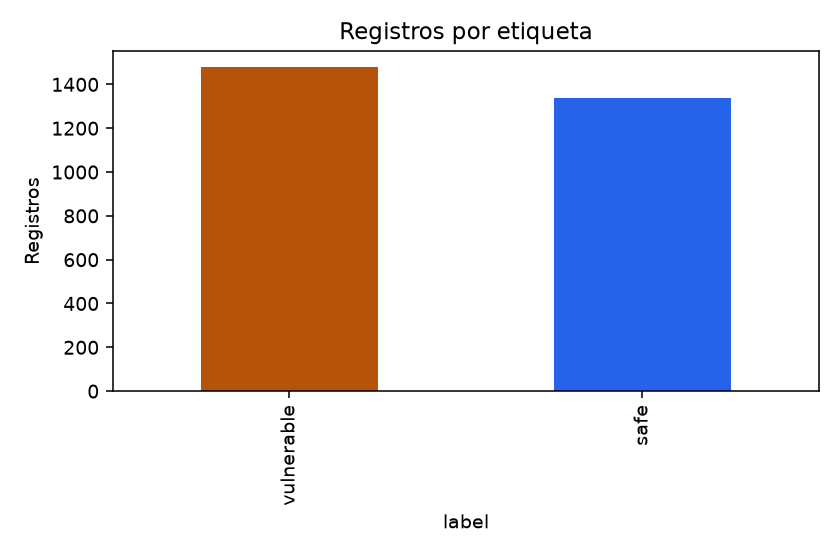

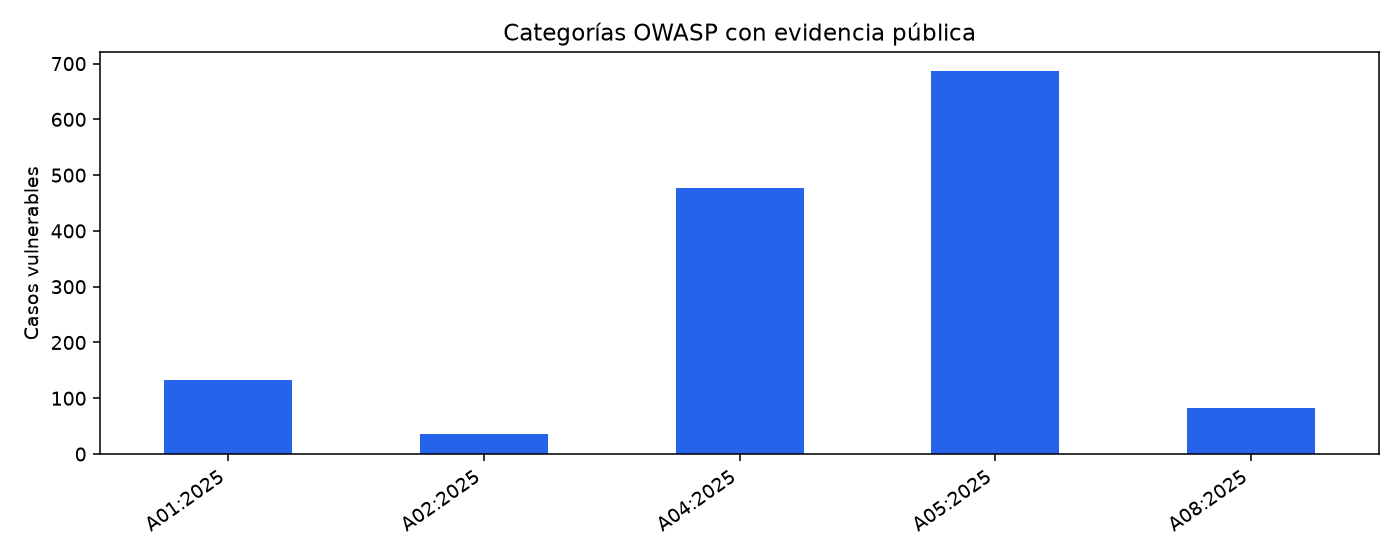

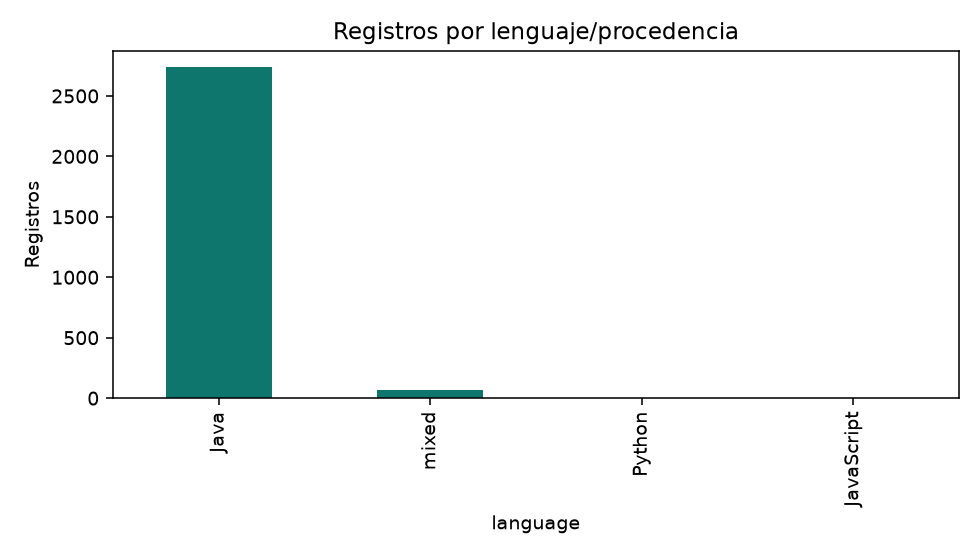

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'reports/distribucion_etiquetas.png')))
display(Image(filename=str(ROOT / 'reports/distribucion_owasp.png')))
display(Image(filename=str(ROOT / 'reports/distribucion_lenguajes.png')))

## 3. Modify

La representación combina TF-IDF de unigramas/bigramas y caracteres con señales estáticas convertidas en variables. Las señales no asignan una categoría: sus pesos son aprendidos por los clasificadores.

In [4]:
from vulnminer.features import make_vectorizer
vectorizer = make_vectorizer()
X_sample = vectorizer.fit_transform(data['code'].astype(str).head(100))
print('Matriz exploratoria:', X_sample.shape, 'no-cero:', X_sample.nnz)

Matriz exploratoria: (100, 16893) no-cero: 372572


## 4. Model

Se comparan Regresión Logística y Complement Naive Bayes. Los modelos multietiqueta separan OWASP Top 10:2025 y OWASP API Security Top 10:2023.

In [5]:
train_ns = runpy.run_path(str(ROOT / 'scripts/train.py'))
metrics = train_ns['train'](ROOT / 'data/vulnerabilities.csv', ROOT / 'models', ROOT / 'reports')
print('Modelo elegido:', metrics['selected_binary_model'])

{
  "dataset": "data\\vulnerabilities.csv",
  "public_benchmark_records": 2736,
  "synthetic_training_records": 70,
  "teacher_training_records": 10,
  "train_public_records": 1915,
  "validation_public_records": 410,
  "test_public_records": 411,
  "split": "70/15/15 estratificado por etiqueta; validation selecciona el algoritmo; test solo OWASP Benchmark Java 1.2; el proyecto de origen es el mismo y la extrapolación externa no queda demostrada",
  "seed": 42,
  "comparison": {
    "logistic_regression": {
      "accuracy": 0.948780487804878,
      "precision_macro": 0.9497119223505224,
      "recall_macro": 0.9481370306842005,
      "f1_macro": 0.9486457631263457,
      "precision_vulnerable": 0.9360730593607306,
      "recall_vulnerable": 0.9669811320754716,
      "f1_vulnerable": 0.951276102088167,
      "confusion_matrix_labels_safe_vulnerable": [
        [
          184,
          14
        ],
        [
          7,
          205
        ]
      ],
      "classification_report":

## 5. Assess

El split se crea solo con los archivos de OWASP Benchmark; filas docentes/sintéticas se agregan al entrenamiento. La prueba aún comparte proyecto y familias CWE con el entrenamiento. Las métricas son descriptivas del Benchmark, no una validación de despliegue.

In [6]:
import json
assessment = json.loads((ROOT / 'reports/assessment.json').read_text(encoding='utf-8'))
print('Comparación:', {k: {m: round(v[m],4) for m in ['accuracy','precision_macro','recall_macro','f1_macro','recall_vulnerable']} for k,v in assessment['comparison'].items()})
print('Matriz (real/predicho: safe, vulnerable):', assessment['binary_test']['confusion_matrix_labels_safe_vulnerable'])
print('Cobertura OWASP pública en test:', assessment['owasp_public_test_support'])
print('Cobertura API pública en test:', assessment['api_public_test_support'])
print('Limitación:', assessment['limitation'])

Comparación: {'logistic_regression': {'accuracy': 0.9488, 'precision_macro': 0.9497, 'recall_macro': 0.9481, 'f1_macro': 0.9486, 'recall_vulnerable': 0.967}, 'complement_nb': {'accuracy': 0.722, 'precision_macro': 0.7225, 'recall_macro': 0.7205, 'f1_macro': 0.7206, 'recall_vulnerable': 0.7642}}
Matriz (real/predicho: safe, vulnerable): [[189, 9], [8, 205]]
Cobertura OWASP pública en test: {'A01:2025': 12, 'A02:2025': 7, 'A04:2025': 68, 'A05:2025': 107, 'A08:2025': 19}
Cobertura API pública en test: {'API8:2023': 7}
Limitación: Las categorías OWASP sin soporte público proceden solo de casos controlados sintéticos y no tienen evaluación independiente. Las etiquetas CWE-OWASP son mapeos curados orientativos, no equivalencias normativas.
